# 可选实验：代价函数
<figure>
    <center> <img src="./images/C1_W1_L3_S2_Lecture_b.png"  style="width:1000px;height:200px;" ></center>
</figure>


## 目标
在本实验中，你将：
- 实现并探索用于单变量线性回归的 `cost`（代价）函数。


## 工具
在本实验中，我们将使用：
- NumPy，一个常用的科学计算库
- Matplotlib，一个常用的数据绘图库
- 本地目录中 lab_utils_uni.py 文件里的本地绘图例程


In [1]:
# !pip install ipympl

import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
from lab_utils_uni import plt_intuition, plt_stationary, plt_update_onclick, soup_bowl
plt.style.use('./deeplearning.mplstyle')

## 问题描述

你希望得到一个能够根据房屋面积预测房价的模型。
让我们沿用上一个实验中的两个数据点——一套 1000 平方英尺的房子以 \$300,000 售出，一套 2000 平方英尺的房子以 \$500,000 售出。


| 面积 (1000 sqft)     | 价格 (1000 美元) |
| -------------------| ------------------------ |
| 1                 | 300                      |
| 2                 | 500                      |


In [2]:
x_train = np.array([1.0, 2.0])           #(面积，单位：1000 平方英尺)
y_train = np.array([300.0, 500.0])           #(价格，单位：1000 美元)


## 计算代价
在这个作业中，'cost'（代价）一词可能有点令人困惑，因为数据本身就是房价（housing cost）。在这里，cost 衡量的是我们的模型对房屋目标价格预测的好坏程度。而对于房屋数据本身，则使用 'price'（价格）一词。

单变量代价的公式为：
  $$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2 \tag{1}$$

其中
  $$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{2}$$

- $f_{w,b}(x^{(i)})$ 是我们使用参数 $w,b$ 对样本 $i$ 作出的预测。
- $(f_{w,b}(x^{(i)}) -y^{(i)})^2$ 是目标值与预测值之差的平方。
- 这些差值对所有 $m$ 个样本求和，再除以 `2m`，得到代价 $J(w,b)$。
>注意：在讲课中，求和范围通常是从 1 到 m，而代码中则是从 0 到 m-1。


下面的代码通过对每个样本循环来计算代价。每次循环中：
- 计算预测值 `f_wb`
- 计算目标值与预测值之差，并对其求平方。
- 将其累加到总代价中。


In [3]:
def compute_cost(x, y, w, b):
    """
    计算线性回归的代价函数。

    参数:
      x (ndarray (m,)): 数据，m 个样本
      y (ndarray (m,)): 目标值
      w,b (scalar)    : 模型参数

    返回
        total_cost (float): 使用 w,b 作为线性回归参数
               拟合 x 和 y 中数据点的代价
    """
    # 训练样本数量
    m = x.shape[0]

    cost_sum = 0
    for i in range(m):
        f_wb = w * x[i] + b
        cost = (f_wb - y[i]) ** 2
        cost_sum = cost_sum + cost
    total_cost = (1 / (2 * m)) * cost_sum

    return total_cost


## 代价函数的直观理解


<img align="left" src="./images/C1_W1_Lab02_GoalOfRegression.PNG"    style=" width:380px; padding: 10px;  " /> 你的目标是找到一个模型 $f_{w,b}(x) = wx + b$，其参数为 $w,b$，能够根据输入 $x$ 准确地预测房屋价值。代价衡量的是模型在训练数据上的准确程度。

上面的代价公式 (1) 表明，如果能够选取 $w$ 和 $b$ 使得预测值 $f_{w,b}(x)$ 与目标数据 $y$ 相匹配，那么 $(f_{w,b}(x^{(i)}) - y^{(i)})^2 $ 这一项将为零，代价也就被最小化。在这个简单的两点示例中，你完全可以做到这一点！

在上一个实验中，你确定了 $b=100$ 是一个最优解，因此让我们把 $b$ 设为 100，并专注于 $w$。

<br/>
在下面，使用滑块控件来选择使代价最小的 $w$ 值。图形更新可能需要几秒钟。


In [4]:
plt_intuition(x_train,y_train)

interactive(children=(IntSlider(value=150, description='w', max=400, step=10), Output()), _dom_classes=('widge…

图中包含几个值得一提的点。
- 当 $w = 200$ 时代价最小，这与上一个实验的结果一致
- 由于代价公式中对目标值与预测值之差进行了平方，因此当 $w$ 过大或过小时，代价都会迅速增大。
- 使用通过最小化代价所选取的 `w` 和 `b`，可以得到一条完美拟合数据的直线。


## 代价函数可视化——3D

你可以通过 3D 绘图或等高线图来观察代价如何随 `w` 和 `b` *两者* 变化。
值得注意的是，本课程中的一些绘图可能会相当复杂。绘图例程已经提供，虽然阅读这些代码以熟悉其方法可能具有启发性，但并非成功完成课程所必需。这些例程位于本地目录的 lab_utils_uni.py 中。


### 更大的数据集
观察一个包含更多数据点的场景会很有启发性。这个数据集包含了不在同一直线上的数据点。这对代价公式意味着什么？我们能否找到使代价为 0 的 $w$ 和 $b$？


In [7]:
x_train = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y_train = np.array([250, 300, 480,  430,   630, 730,])


在等高线图中，点击某个点以选择 `w` 和 `b`，从而达到最低的代价。使用等高线来引导你的选择。注意，图形更新可能需要几秒钟。


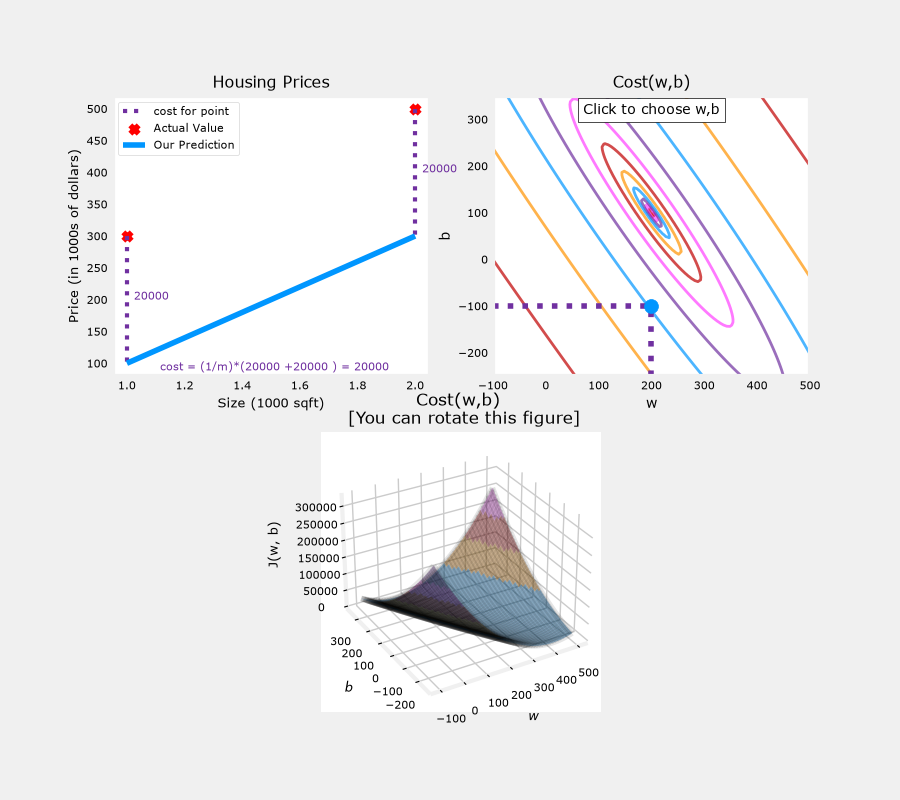

In [5]:
plt.close('all') 
fig, ax, dyn_items = plt_stationary(x_train, y_train)
updater = plt_update_onclick(fig, ax, x_train, y_train, dyn_items)

在上方，注意左图中的虚线。它们表示训练集中每个样本对代价所贡献的部分。在这种情况下，约 $w=209$ 和 $b=2.4$ 的取值能提供最低的代价。注意，由于我们的训练样本不在同一条直线上，因此最小代价并不为零。


### 凸的代价曲面
代价函数对损失进行平方，这一事实保证了 '误差曲面'（error surface）是凸的，就像一个汤碗。它始终存在一个最小值，可以通过沿所有维度的梯度方向到达。在上一个图中，由于 $w$ 和 $b$ 两个维度的尺度不同，这一点不易被识别。下面这个图（$w$ 和 $b$ 是对称的）在讲课中展示过：


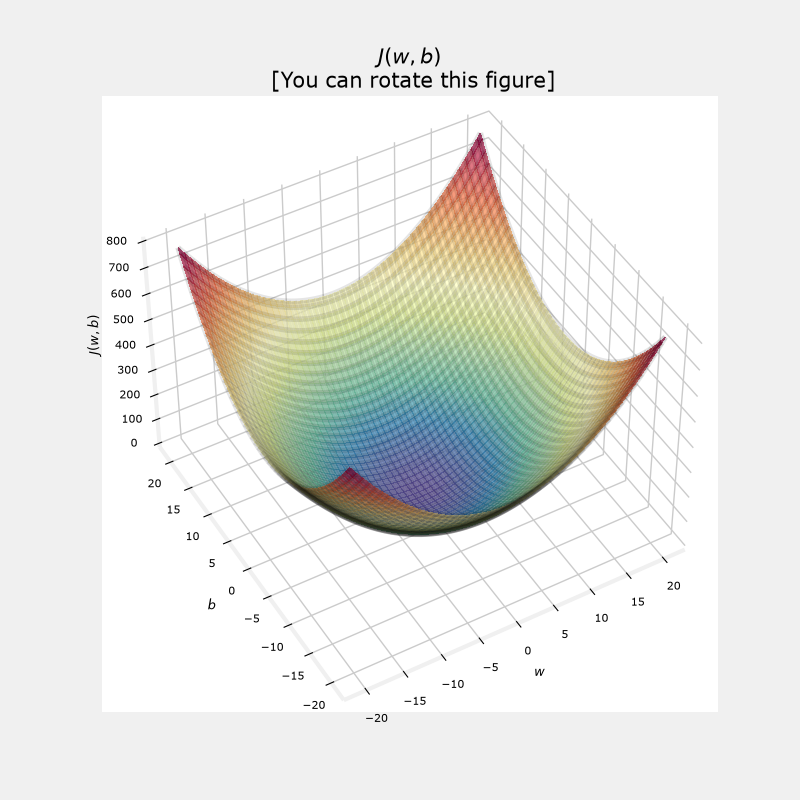

In [6]:
soup_bowl()

# 恭喜！
你已经学到了以下内容：
 - 代价公式提供了一种衡量你的预测与训练数据匹配程度的方法。
 - 最小化代价可以得到 $w$、$b$ 的最优取值。
